In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock
import scipy.stats

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}

def RMSE(pred, true):
    return np.sqrt(np.mean((pred - true) ** 2))


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [2]:

base_path = "../AXA_peptides/"

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open_PH = []
pop_open_PH_err = []
rg = []
rg_err = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath_PH = os.path.join(base_path, aa, "SIM", "AmideHcoord", "amideH_water_coord_frames_traj_system_protein_centered_0.26nm.npy")
    filepath_rg = os.path.join(base_path, aa, "SIM", "BB_rg_data", "rg_traj_fit.txt")

    if not os.path.isfile(filepath_PH):
        print(f"Skipping {aa}: M10 file not found.")
        continue

    Hcoord = np.load(filepath_PH)[:,1] # only middle residue
    O = (Hcoord>=2)*1
    rg_data = np.loadtxt(filepath_rg) 

    pop_open_PH.append(np.mean(O))
    rg.append(np.mean(rg_data))

    # errors PH
    reblock_data = pyblock.blocking.reblock(O)
    opt = pyblock.blocking.find_optimal_block(len(O), reblock_data)[0]
    err_fopen_PH = reblock_data[opt][4]

    # errors rg
    reblock_data = pyblock.blocking.reblock(rg_data)
    opt = pyblock.blocking.find_optimal_block(len(rg_data), reblock_data)[0]
    err_rg = reblock_data[opt][4]

    # append errors
    pop_open_PH_err.append(err_fopen_PH)
    rg_err.append(err_rg)
       

df['p_open_PH'] = np.round(pop_open_PH, 4)
df['p_open_PH ±'] = np.round(pop_open_PH_err, 4)
df['rg'] = np.round(rg, 4)
df['rg ±'] = np.round(rg_err, 4)
df['aa'] = code

# peptide correction factor - error-weighted average 
#peptide_correction_factor = np.mean(df['p_open_PH'])
peptide_correction_factor = np.average(df['p_open_PH'], weights=1/df['p_open_PH ±']**2)
print(peptide_correction_factor)

# calculate protection factors
df["PF_PH"] = np.round(1 / df['p_open_PH'], 4)
df["PF_PH ±"] = np.round(df['p_open_PH ±'] / (df['p_open_PH'] ** 2), 4)
df["PF_PH_corr"] = np.round(peptide_correction_factor / df['p_open_PH'], 4)
df["PF_PH_corr ±"] = np.round(df['p_open_PH ±'] / (df['p_open_PH'] ** 2), 4)

# save
df.to_csv(f'AXA_tripeptides_PH_PF_rg.csv', index=False)








0.025651157342721956


In [3]:
df

,AA,p_open_PH,p_open_PH ±,rg,rg ±,aa,PF_PH,PF_PH ±,PF_PH_corr,PF_PH_corr ±
0,Ala,0.0386,0.0023,0.3600,0.0011,A,25.9067,1.5437,0.6645,1.5437
1,Arg,0.0349,0.0021,0.3588,0.0033,R,28.6533,1.7241,0.7350,1.7241
2,Asn,0.0337,0.0024,0.3567,0.0012,N,29.6736,2.1133,0.7612,2.1133
3,Asp,0.0198,0.0015,0.3465,0.0026,D,50.5051,3.8261,1.2955,3.8261
4,Cys,0.0285,0.0017,0.3583,0.0012,C,35.0877,2.0930,0.9000,2.0930
5,Gln,0.0268,0.0020,0.3604,0.0018,Q,37.3134,2.7846,0.9571,2.7846
6,Glu,0.0276,0.0018,0.3555,0.0019,E,36.2319,2.3629,0.9294,2.3629
7,Gly,0.0650,0.0027,0.3495,0.0008,G,15.3846,0.6391,0.3946,0.6391
8,His,0.0249,0.0019,0.3487,0.0022,H,40.1606,3.0645,1.0302,3.0645
9,Ile,0.0132,0.0012,0.3592,0.0016,I,75.7576,6.8871,1.9433,6.8871


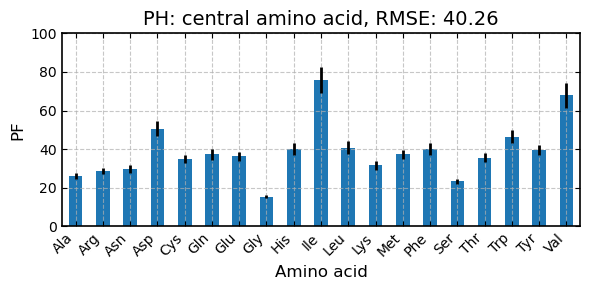

In [5]:
# plot PFs PH and add RMSE to title

df.plot(x='AA', y='PF_PH', yerr='PF_PH ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('PH: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_PH'], np.ones(len(df))), 4)))
plt.ylim(0,100)
plt.tight_layout()
plt.savefig('PF_PH.png')

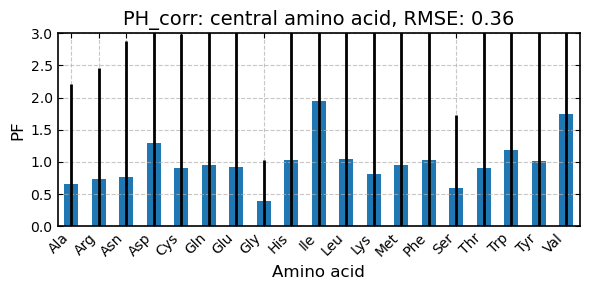

In [6]:
# plot PFs PH and add RMSE to title

df.plot(x='AA', y='PF_PH_corr', yerr='PF_PH_corr ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('PH_corr: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_PH_corr'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_PH_corr.png')

In [7]:
print(peptide_correction_factor)

0.025651157342721956
